<div style="border-left: 5px solid #48C7E8; padding: 8px 0 8px 18px; margin: 0 0 12px;">
<div style="font-family: sans-serif; font-size: 12px; letter-spacing: .15em; color: #1498BC; font-weight: 700;">DEEPDIVE · AI BOOTCAMP / 01</div>
<h1 style="margin: 6px 0 2px; font-size: 30px;">Od surowych danych do pierwszej analizy</h1>
<div style="color: #6b7280;">Python · pandas · preprocessing · EDA</div>
</div>

**Cel:** przygotować zbiór danych do analizy i sprawdzić, co się w nim znajduje.

**Dane:** `penguins.csv` — syntetyczny zbiór o pingwinach, celowo zawierający błędy. Nie są to pomiary z rzeczywistego badania.

**Zasady:** uruchamiaj komórki od góry (`Shift + Enter`). Uzupełniaj wyłącznie miejsca oznaczone `# TODO`. Plik `penguins.csv` musi leżeć obok notebooka.

**Czas:** ~30–40 min · **Biblioteki:** `pandas`, `matplotlib`

### 01 / Wczytanie danych

Wczytaj `penguins.csv` do zmiennej `df` i wyświetl pierwsze pięć wierszy.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# TODO: wczytaj plik CSV
df = pd.read_csv('penguins.csv')

# TODO: wyświetl pierwsze 5 wierszy
print(df.head())

  penguin_id    species     island  bill_length_mm  flipper_length_mm  \
0       P001     Adelie  Torgersen            40.9                178   
1       P002  Chinstrap      Dream            44.8                197   
2       P003  Chinstrap      Dream            47.7                198   
3       P004     Adelie      Dream            35.5                178   
4       P005     Adelie     Biscoe            37.8                198   

   body_mass_g     sex  
0       2950.0  female  
1       4600.0    male  
2       3300.0  female  
3       3700.0  female  
4          NaN  female  


### 02 / Pierwszy przegląd

Sprawdź **liczbę wierszy i kolumn**, nazwy i typy kolumn oraz podstawowe statystyki dla kolumn liczbowych.

In [9]:
# TODO: rozmiar tabeli
print(df.shape)

# TODO: typy danych i braki
print(df.info())

# TODO: statystyki opisowe
print(df.describe())

(98, 7)
<class 'pandas.DataFrame'>
RangeIndex: 98 entries, 0 to 97
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   penguin_id         98 non-null     str    
 1   species            98 non-null     str    
 2   island             98 non-null     str    
 3   bill_length_mm     95 non-null     float64
 4   flipper_length_mm  98 non-null     int64  
 5   body_mass_g        94 non-null     float64
 6   sex                94 non-null     str    
dtypes: float64(2), int64(1), str(4)
memory usage: 5.5 KB
None
       bill_length_mm  flipper_length_mm   body_mass_g
count       95.000000          98.000000     94.000000
mean        45.166316         199.714286   4314.893617
std          5.534642          12.326319   2681.225344
min         29.400000         178.000000   2150.000000
25%         41.000000         190.000000   3512.500000
50%         45.000000         198.000000   3950.000000
75%         49.350000

### 03 / Brakujące wartości

Policz brakujące wartości w każdej kolumnie. Które kolumny wymagają uwagi?

In [10]:
# TODO: liczba braków w każdej kolumnie
print(df.isnull().sum())

penguin_id           0
species              0
island               0
bill_length_mm       3
flipper_length_mm    0
body_mass_g          4
sex                  4
dtype: int64


### 04 / Duplikaty

Sprawdź, ile wierszy jest identycznych, a następnie usuń duplikaty.

In [11]:
# TODO: policz duplikaty
print("Liczba duplikatow:", df.duplicated().sum())

# TODO: usuń powtarzające się wiersze
df = df.drop_duplicates()

# TODO: sprawdź rozmiar po czyszczeniu
print("Nowy rozmiar tabeli:", df.shape)

Liczba duplikatow: 2
Nowy rozmiar tabeli: (96, 7)


### 05 / Niespójne kategorie

Wyświetl wartości w kolumnie `sex`. Ujednolić zapis tak, aby zostały tylko `female`, `male` i braki.

In [22]:
# TODO: jakie wartości występują w kolumnie sex?
print(df['sex'].unique())

# TODO: usuń spacje i zamień litery na małe
df['sex'] = df['sex'].astype(str).str.strip().str.lower()
df['sex'] = df['sex'].replace(['nan', 'none', ''], pd.NA)

# TODO: sprawdź wynik
print(df['sex'].value_counts(dropna=False))

Przed: <StringArray>
['female', 'male', 'unknown']
Length: 3, dtype: str

Po czyszczeniu:
sex
female     50
male       42
unknown     4
Name: count, dtype: int64


### 06 / Wartości odstające

Sprawdź maksymalną masę pingwina. **Na potrzeby tego ćwiczenia** uznaj masę powyżej `8000 g` za błąd i zastąp ją brakiem (`NaN`).

In [14]:
# TODO: maksimum masy
print("Maksimum przed:", df['body_mass_g'].max())

# TODO: ustaw NaN dla masy > 8000 g
df.loc[df['body_mass_g'] > 8000, 'body_mass_g'] = pd.NA

# TODO: sprawdź maksimum jeszcze raz
print("Maksimum po:", df['body_mass_g'].max())

Maksimum przed: 29000.0
Maksimum po: 5750.0


### 07 / Uzupełnianie braków

Uzupełnij braki w `body_mass_g` i `bill_length_mm` **medianą**, a braki w `sex` etykietą `unknown`. Nie usuwaj wierszy.

In [15]:
# TODO: mediana masy
df['body_mass_g'] = df['body_mass_g'].fillna(df['body_mass_g'].median())

# TODO: mediana długości dzioba
df['bill_length_mm'] = df['bill_length_mm'].fillna(df['bill_length_mm'].median())

# TODO: brak płci -> "unknown"
df['sex'] = df['sex'].fillna('unknown')

# TODO: kontrola pozostałych braków
print(df.isnull().sum())

penguin_id           0
species              0
island               0
bill_length_mm       0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


### 08 / Pierwsze EDA

Sprawdź liczebność gatunków i średnią masę dla każdego gatunku. Następnie narysuj histogram masy.

species
Adelie       36
Chinstrap    35
Gentoo       25
Name: count, dtype: int64
species
Adelie       3630.555556
Chinstrap    3772.857143
Gentoo       5016.000000
Name: body_mass_g, dtype: float64


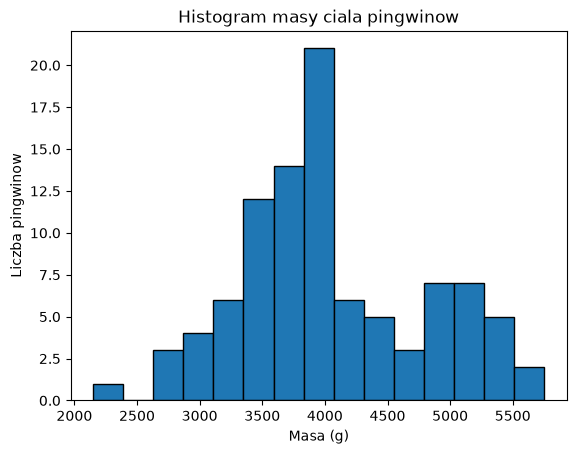

In [17]:
# TODO: liczebność gatunków
print(df['species'].value_counts())

# TODO: średnia masa według species
print(df.groupby('species')['body_mass_g'].mean())

# TODO: histogram masy (np. 15 przedziałów)
df['body_mass_g'].plot(kind='hist', bins=15, edgecolor='black')
plt.xlabel('Masa (g)')
plt.ylabel('Liczba pingwinow')
plt.title('Histogram masy ciala pingwinow')
plt.show()

In [18]:
# TODO: liczba pozostałych braków
print("Suma braków:", df.isnull().sum().sum())

# TODO: liczba duplikatów
print("Liczba duplikatów:", df.duplicated().sum())

# TODO: zapisz CSV bez indeksu
df.to_csv('penguins_clean.csv', index=False)

Suma braków: 0
Liczba duplikatów: 0


---
### Checkpoint

Odpowiedz w 1–2 zdaniach:

1. Dlaczego **mediana** może być lepsza od średniej przy uzupełnianiu braków?

   Mediana jest odporna na wartości odstające (błędy w danych), które mogłyby mocno zniekształcić średnią.
2. Dlaczego nie każdą wartość odstającą należy automatycznie usuwać?

   Wartości odstające mogą być poprawnymi, naturalnymi skrajnościami w przyrodzie, a nie błędami pomiarowymi.
3. Jakie informacje o gatunkach widać w `value_counts()` i `groupby()`?

   value_counts() pokazuje liczebność poszczególnych gatunków, a groupby() pozwala porównać ich średnią masę.

**Gotowe.** Masz uporządkowany zbiór i pierwsze obserwacje z EDA.